# Case 3 — Which sentiment method best predicts star rating?

**DV:** `star_rating` (from `knn_sentiment score.csv`)
**IVs:**
- `predicted_sentiment` — KNN (supervised), from `knn_sentiment score.csv`
- `net_score` — SentiStrength (lexicon), from `sentistrength_sentiment score.csv`
- `vader_compound` — VADER (lexicon), from `Vader_sentiment score.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.precision", 4)

## 1. Load and merge on `reviewer_id`

In [2]:
knn = pd.read_csv("../results/knn_sentiment score.csv", encoding="utf-8-sig")
senti = pd.read_csv("../results/sentistrength_sentiment score.csv")
vader = pd.read_csv("../results/Vader_sentiment score.csv")

df = (knn[["reviewer_id", "star_rating", "predicted_sentiment"]]
      .merge(senti[["reviewer_id", "net_score"]], on="reviewer_id", how="inner", validate="1:1")
      .merge(vader[["reviewer_id", "vader_compound"]], on="reviewer_id", how="inner", validate="1:1"))

# star_rating in the SentiStrength file should match the KNN file
check = knn[["reviewer_id", "star_rating"]].merge(senti[["reviewer_id", "star_rating"]], on="reviewer_id")
assert (check.star_rating_x == check.star_rating_y).all()

print(df.shape, "| missing values:", df.isna().sum().sum())
df.head()

(200, 5) | missing values: 0


,reviewer_id,star_rating,predicted_sentiment,net_score,vader_compound
0,2516,5,1,1,0.5859
1,3102,4,1,0,0.0000
2,8694,5,1,0,-0.2960
3,9314,5,1,2,0.4404
4,17105,5,1,2,0.9584


## 2. Descriptive statistics and correlations

In [3]:
ivs = ["predicted_sentiment", "net_score", "vader_compound"]
cols = ["star_rating"] + ivs
display(df[cols].describe().T)
display(df["star_rating"].value_counts().sort_index().rename("n reviews"))
display(df[cols].corr().round(3))

,count,mean,std,min,25%,50%,75%,max
star_rating,200.0,4.3500,1.1809,1.0000,4.0000,5.0000,5.0000,5.000
predicted_sentiment,200.0,0.7000,0.6340,-1.0000,1.0000,1.0000,1.0000,1.000
net_score,200.0,1.4900,1.3709,-3.0000,1.0000,2.0000,2.0000,4.000
vader_compound,200.0,0.5195,0.4573,-0.8655,0.2971,0.7053,0.8622,0.992


star_rating
1     12
2      7
3     23
4     15
5    143
Name: n reviews, dtype: int64

,star_rating,predicted_sentiment,net_score,vader_compound
star_rating,1.000,0.933,0.583,0.615
predicted_sentiment,0.933,1.000,0.511,0.543
net_score,0.583,0.511,1.000,0.693
vader_compound,0.615,0.543,0.693,1.000


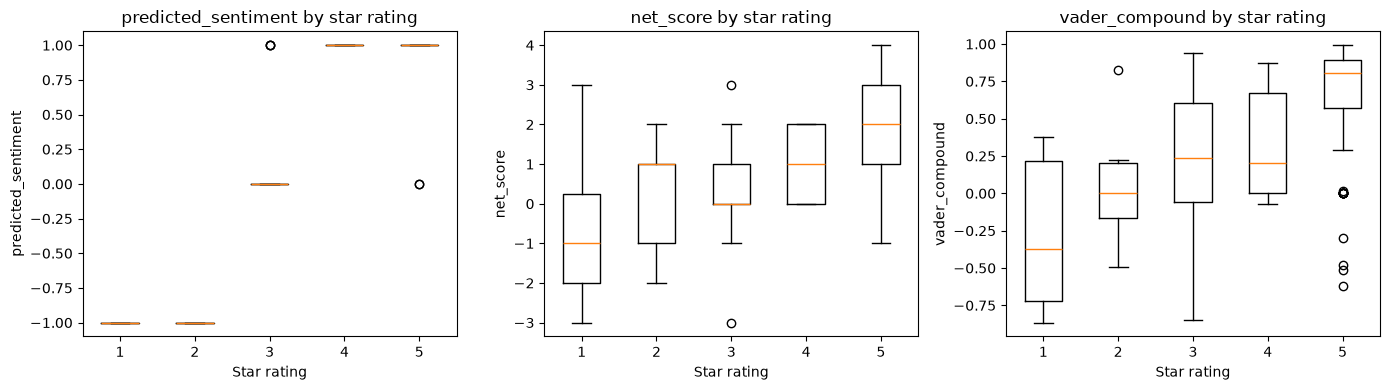

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, x in zip(axes, ivs):
    groups = [df.loc[df.star_rating == s, x] for s in sorted(df.star_rating.unique())]
    ax.boxplot(groups, tick_labels=sorted(df.star_rating.unique()))
    ax.set_xlabel("Star rating"); ax.set_ylabel(x); ax.set_title(f"{x} by star rating")
plt.tight_layout(); plt.show()

## 3. Simple regressions — each method on its own

In [5]:
rows = []
for x in ivs:
    m = smf.ols(f"star_rating ~ {x}", data=df).fit(cov_type="HC3")
    rows.append({"method": x, "coef": m.params[x], "robust SE": m.bse[x], "p-value": m.pvalues[x],
                 "R²": m.rsquared, "adj. R²": m.rsquared_adj, "AIC": m.aic})
simple = pd.DataFrame(rows).set_index("method")
simple

,coef,robust SE,p-value,R²,adj. R²,AIC
method,,,,,,
predicted_sentiment,1.7375,0.0556,5.3048e-214,0.8703,0.8697,228.5463
net_score,0.5019,0.0594,3.1021e-17,0.3395,0.3361,554.1298
vader_compound,1.5892,0.1928,1.6596e-16,0.3787,0.3755,541.8977


## 4. Multivariate regression (all three methods)

`star_rating = β0 + β1·KNN + β2·SentiStrength + β3·VADER + ε`

Standard errors are heteroskedasticity-robust (HC3), because the DV is bounded 1–5 and heavily skewed toward 5 stars.

In [6]:
formula = "star_rating ~ predicted_sentiment + net_score + vader_compound"
full = smf.ols(formula, data=df).fit(cov_type="HC3")
print(full.summary())

                            OLS Regression Results                            
Dep. Variable:            star_rating   R-squared:                       0.891
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     487.6
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.33e-90
Time:                        07:53:35   Log-Likelihood:                -95.161
No. Observations:                 200   AIC:                             198.3
Df Residuals:                     196   BIC:                             211.5
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               3.0151    

### 4a. Standardized coefficients

The three scores are on different scales (KNN −1/0/1, SentiStrength −4…+4, VADER −1…+1), so raw coefficients can't be compared directly. Standardizing everything (z-scores) gives the effect of a 1-SD change in each score, in SDs of star rating.

In [7]:
z = df[cols].apply(lambda c: (c - c.mean()) / c.std())
std_model = smf.ols(formula, data=z).fit(cov_type="HC3")
std_coef = pd.DataFrame({"beta (standardized)": std_model.params[ivs],
                         "p-value": std_model.pvalues[ivs]})
std_coef

,beta (standardized),p-value
predicted_sentiment,0.8328,2.3528e-75
net_score,0.0841,2.0778e-02
vader_compound,0.1053,3.6655e-03


### 4b. Multicollinearity (VIF)

In [8]:
X = df[ivs].assign(const=1.0)
pd.Series([variance_inflation_factor(X.values, i) for i in range(len(ivs))], index=ivs, name="VIF")

predicted_sentiment    1.4913
net_score              2.0252
vader_compound         2.1203
Name: VIF, dtype: float64

### 4c. Unique contribution of each method (drop-one ΔR²)

How much adjusted R² is lost when each method is removed from the full model.

In [9]:
rows = []
for x in ivs:
    others = [o for o in ivs if o != x]
    reduced = smf.ols("star_rating ~ " + " + ".join(others), data=df).fit()
    rows.append({"method dropped": x,
                 "adj. R² without it": reduced.rsquared_adj,
                 "ΔR² (unique contribution)": full.rsquared - reduced.rsquared})
pd.DataFrame(rows).set_index("method dropped").assign(**{"full adj. R²": full.rsquared_adj})

,adj. R² without it,ΔR² (unique contribution),full adj. R²
method dropped,,,
predicted_sentiment,0.4198,0.4651,0.889
net_score,0.8861,0.0035,0.889
vader_compound,0.8843,0.0052,0.889


## 5. Robustness: is the KNN result a fair comparison?

`sentiment` (the KNN training label) is derived directly from `star_rating` (1–2 → −1, 3 → 0, 4–5 → +1). If `predicted_sentiment` was produced on the same reviews the KNN was trained on, its fit with star rating is partly mechanical (in-sample), while VADER and SentiStrength never saw the ratings.

In [10]:
knn_full = knn.copy()
display(pd.crosstab(knn_full.star_rating, knn_full.sentiment).rename_axis(index="star", columns="label"))
acc = (knn_full.sentiment == knn_full.predicted_sentiment).mean()
print(f"KNN agreement with star-derived label: {acc:.1%}")

label,-1,0,1
star,,,
1,12,0,0
2,7,0,0
3,0,23,0
4,0,0,15
5,0,0,143


KNN agreement with star-derived label: 97.5%


In [11]:
# Model with only the two lexicon methods (both fully independent of the ratings)
lex = smf.ols("star_rating ~ net_score + vader_compound", data=df).fit(cov_type="HC3")
print(lex.summary().tables[1])
print(f"adj. R² = {lex.rsquared_adj:.3f}")
z_lex = smf.ols("star_rating ~ net_score + vader_compound", data=z).fit()
print("standardized betas:\n", z_lex.params[["net_score", "vader_compound"]].round(3))

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          3.4181      0.148     23.057      0.000       3.128       3.709
net_score          0.2589      0.089      2.899      0.004       0.084       0.434
vader_compound     1.0513      0.283      3.719      0.000       0.497       1.605
adj. R² = 0.420
standardized betas:
 net_score         0.301
vader_compound    0.407
dtype: float64


## 6. Summary table for the report

In [12]:
def col(m, name):
    s = {}
    for x in ivs + ["Intercept"]:
        if x in m.params:
            stars = "***" if m.pvalues[x] < .001 else "**" if m.pvalues[x] < .01 else "*" if m.pvalues[x] < .05 else ""
            s[x] = f"{m.params[x]:.3f}{stars} ({m.bse[x]:.3f})"
        else:
            s[x] = ""
    s["N"] = int(m.nobs); s["R²"] = f"{m.rsquared:.3f}"; s["adj. R²"] = f"{m.rsquared_adj:.3f}"; s["AIC"] = f"{m.aic:.1f}"
    return pd.Series(s, name=name)

models = {f"(1) KNN only": smf.ols("star_rating ~ predicted_sentiment", df).fit(cov_type="HC3"),
          f"(2) SentiStrength only": smf.ols("star_rating ~ net_score", df).fit(cov_type="HC3"),
          f"(3) VADER only": smf.ols("star_rating ~ vader_compound", df).fit(cov_type="HC3"),
          f"(4) Lexicon only": lex,
          f"(5) Full model": full}
table = pd.concat([col(m, n) for n, m in models.items()], axis=1)
print("Coefficient (robust HC3 SE); * p<.05, ** p<.01, *** p<.001")
table

Coefficient (robust HC3 SE); * p<.05, ** p<.01, *** p<.001


,(1) KNN only,(2) SentiStrength only,(3) VADER only,(4) Lexicon only,(5) Full model
predicted_sentiment,1.738*** (0.056),,,,1.551*** (0.084)
net_score,,0.502*** (0.059),,0.259** (0.089),0.072* (0.031)
vader_compound,,,1.589*** (0.193),1.051*** (0.283),0.272** (0.094)
Intercept,3.134*** (0.055),3.602*** (0.134),3.524*** (0.150),3.418*** (0.148),3.015*** (0.058)
N,200,200,200,200,200
R²,0.870,0.339,0.379,0.426,0.891
adj. R²,0.870,0.336,0.376,0.420,0.889
AIC,228.5,554.1,541.9,528.2,198.3
